# Entrega Final: Churn de clientes en telecomunicaciones

## 1. Definición del problema y carga

**Contexto.** Una empresa de telecomunicaciones pierde clientes todos los meses (*churn*). Retener a un cliente cuesta menos que conseguir uno nuevo, por eso conviene anticipar quién está por irse.

**Objetivo / pregunta analítica.** ¿Se puede predecir, a partir de las características del contrato y del servicio, si un cliente se va (`Churn = Yes`) o se queda (`Churn = No`)? ¿Qué factores se relacionan más con la fuga?

**Fuente de datos.** Dataset *Telco Customer Churn*: 7.043 clientes y 21 columnas (datos del cliente, servicios contratados, tipo de contrato, cargos y la variable objetivo `Churn`).

Introducción: este dataset trata sobre el churn de clientes de una empresa de telecomunicaciones. Clasifica si los clientes dejaron de contratar a la empresa o si siguieron. Tienen una clave primaria y diferentes columnas como el tiempo que llevan en la empresa, los servicios y que contratan y los que no. Es un problema de clasificación, se intentará predecir si un cliente se irá o se quedará.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, recall_score, precision_score, silhouette_score, roc_curve, confusion_matrix,
                             roc_auc_score, precision_recall_curve)

In [ ]:
from pathlib import Path

# El CSV está en data/. Si lo movés, ajustá esta ruta.
CSV = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
candidatas = [
    Path("../data") / CSV,                 # corriendo desde notebooks/
    Path("data") / CSV,                    # corriendo desde la raíz del repo
    Path(CSV),                             # CSV subido directo a Colab
    Path("/content/drive/MyDrive") / CSV,  # CSV en Google Drive
]
ruta = next((p for p in candidatas if p.exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No encontré {CSV}. Revisá data/README.md.")
df = pd.read_csv(ruta)

In [ ]:
display(df.head(5))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Limpieza y Análisis Exploratorio (EDA)

In [ ]:
#Reporte de filas y columnas
print(f"Reporte de filas y columnas: {df.shape}")
#Información del dataset y tipos de las categorías
print(df.info())
print(df.dtypes)
print(df.dtypes.value_counts())

Reporte de filas y columnas: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Pa

En total son 18 columnas de tipo object y tres numéricas. Pero de las 18 object, customerID es solo un identificador y TotalCharges en realidad es numérica, así que las variables categóricas son 16 (incluida Churn). De las numéricas, SeniorCitizen es binaria (0/1), tenure es discreta y MonthlyCharges es continua. El tipo de TotalCharges es object. Esto es incorrecto, debería ser Float, es el cargo total del cliente, que es resultado de tenure multiplicado por monthlycharges. Los clientes nuevos son los que no tienen este cargo total relleno, entonces se rellena con cero, ya que todavía no tienen cargo.

In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)
print(df['TotalCharges'].dtype)

float64


**Duplicados.** Se revisa si hay clientes repetidos y se comprueba que los clientes nuevos (`tenure = 0`) son los que tenían el `TotalCharges` vacío.

In [ ]:
# Filas duplicadas
print("Filas duplicadas:", df.duplicated().sum())
print("IDs de cliente duplicados:", df['customerID'].duplicated().sum())

# Clientes nuevos: tenure = 0, su TotalCharges quedó en 0
display(df[df['tenure'] == 0][['customerID', 'tenure', 'TotalCharges']])

Filas duplicadas: 0
IDs de cliente duplicados: 0


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,0.0
753,3115-CZMZD,0,0.0
936,5709-LVOEQ,0,0.0
1082,4367-NUYAO,0,0.0
1340,1371-DWPAZ,0,0.0
3331,7644-OMVMY,0,0.0
3826,3213-VVOLG,0,0.0
4380,2520-SGTTA,0,0.0
5218,2923-ARZLG,0,0.0
6670,4075-WKNIU,0,0.0


Interpretación: no hay filas ni clientes duplicados, por lo que no hay nada que eliminar. Los clientes con `tenure = 0` son los 11 que tenían el `TotalCharges` vacío, así que rellenar con 0 es coherente: todavía no se les facturó nada.

In [ ]:
#Resumen numérico
display(df.describe(include='number'))
#Diagnóstico de nulos
suma_nulos=df.isnull().sum()
display(suma_nulos)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
dfpd = df.drop(columns=['PaperlessBilling', "StreamingTV", "StreamingMovies"])

Interpretación: tras la corrección, no quedan valores nulos en el dataset (los pocos TotalCharges vacíos fueron imputados en 0, coherente con clientes de tenure = 0, es decir, sin facturación acumulada todavía). Las variables numéricas (tenure, MonthlyCharges, TotalCharges) muestran escalas muy distintas entre sí (por ejemplo, tenure va de 0 a 72 mientras que TotalCharges llega a más de 8000), lo que confirma la necesidad de escalar los datos antes de entrenar modelos sensibles a la escala como la Regresión Logística.

Se eliminaron tres columnas del dataframe que no son relevantes para evaluar la pregunta de negocio.

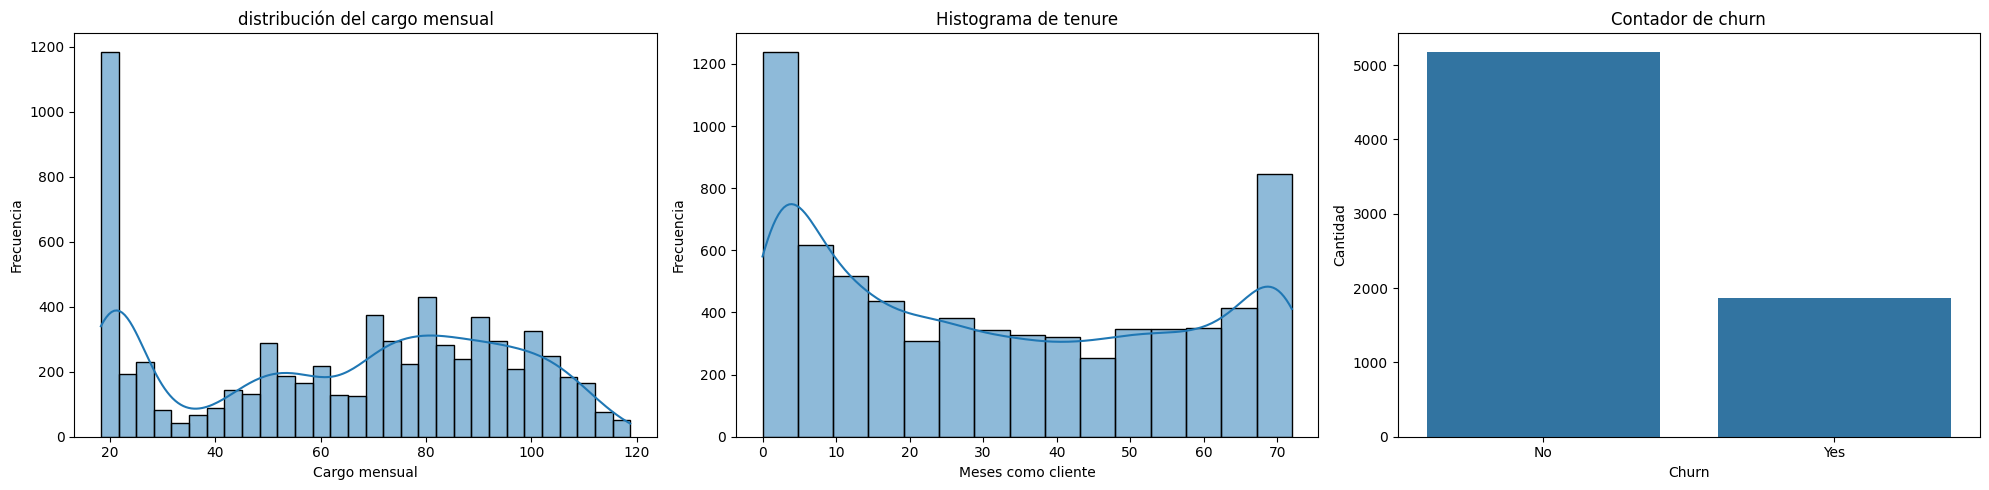

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 5))
sns.histplot(data=dfpd, x="MonthlyCharges",  bins=30, kde=True, ax=axes[0])
axes[0].set_title("distribución del cargo mensual")
axes[0].set_xlabel("Cargo mensual")
axes[0].set_ylabel("Frecuencia")

sns.histplot(data=dfpd, x="tenure", bins=15, kde=True, ax=axes[1])
axes[1].set_title("Histograma de tenure")
axes[1].set_xlabel("Meses como cliente")
axes[1].set_ylabel("Frecuencia")

sns.countplot(data=dfpd, x="Churn", ax=axes[2])
axes[2].set_title("Contador de churn")
axes[2].set_xlabel("Churn")
axes[2].set_ylabel("Cantidad")


plt.tight_layout()

Las tres visualizaciones muestran la distribución de las variables cargo mensual, tenure y Churn (las dos primeras son histogramas y la tercera es un gráfico de barras). Ninguna de las dos numéricas tiene forma de campana: el cargo mensual tiene un pico muy alto en los valores más bajos (alrededor de 20) y otra concentración entre 70 y 100; tenure tiene forma de "U", con muchos clientes nuevos en el primer bin y otro grupo grande de clientes muy antiguos (cerca de 72 meses).
También está la representación de la cantidad de sí Churn o no Churn, muy importante para visualizar nuestra variable a predecir: hay bastantes más clientes que se quedan que clientes que se van.

Text(0.5, 1.0, 'heatmap: correlación entre variables')

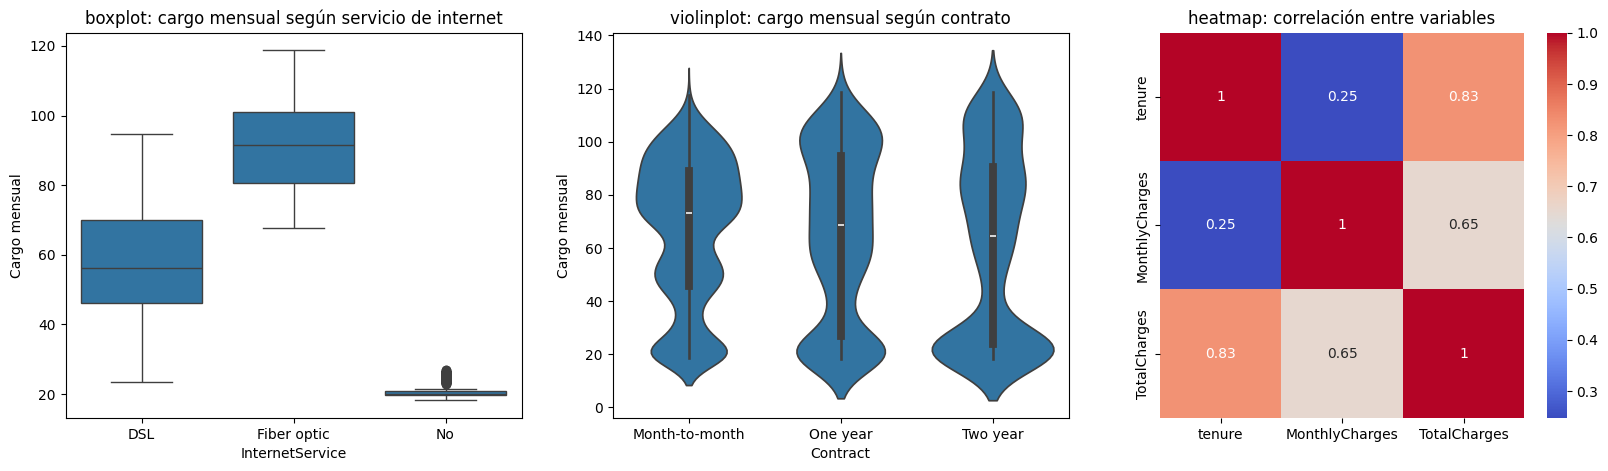

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 5))
sns.boxplot(data=dfpd, x="InternetService", y="MonthlyCharges", ax=axes[0])
axes[0].set_title("boxplot: cargo mensual según servicio de internet")
axes[0].set_ylabel("Cargo mensual")

sns.violinplot(data=dfpd, x="Contract", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("violinplot: cargo mensual según contrato")
axes[1].set_ylabel("Cargo mensual")

matriz_corr = dfpd[["tenure", "MonthlyCharges", "TotalCharges"]].corr()
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", ax=axes[2])
axes[2].set_title("heatmap: correlación entre variables")

Primero, un boxplot que muestra la distribución del cargo mensual según el servicio de internet que tienen (y de los que no tienen). Los cargos de fibra óptica se distribuyen en valores más altos que los de DSL. Ni fibra óptica ni DSL presentan outliers y los dos tienen un rango intercuartílico amplio. Los clientes sin internet tienen un rango intercuartílico muy corto (todos pagan cerca de 20) y por eso aparecen varios puntos fuera de la caja, pero no son valores raros ni errores.

Segundo, un violinplot que muestra la distribución del cargo mensual según el tipo de contrato. Casi no presenta valores atípicos, son distribuciones parecidas. El two year parece que concentra algo más en los valores bajos y month to month es más irregular.

Por último, una matriz de correlación entre las variables numéricas. Hay una fuerte correlación entre la longevidad y los cargos totales (0,83), es lógico que a más tiempo el cliente haya pagado una cantidad total mayor. Baja correlación entre longevidad y cargo mensual (0,25). El cargo no se relaciona con el tiempo que lleva el cliente con el servicio. No tan alta correlación entre el cargo mensual y el cargo total (0,65). Puede ser que los cargos totales altos sean de los que tienen cargo mensual más alto pero no lo llega a explicar del todo.

**Relación con el Churn.** Hasta acá se compararon las variables entre sí, pero falta ver cómo se relacionan con la fuga de clientes, que es lo que se quiere predecir.

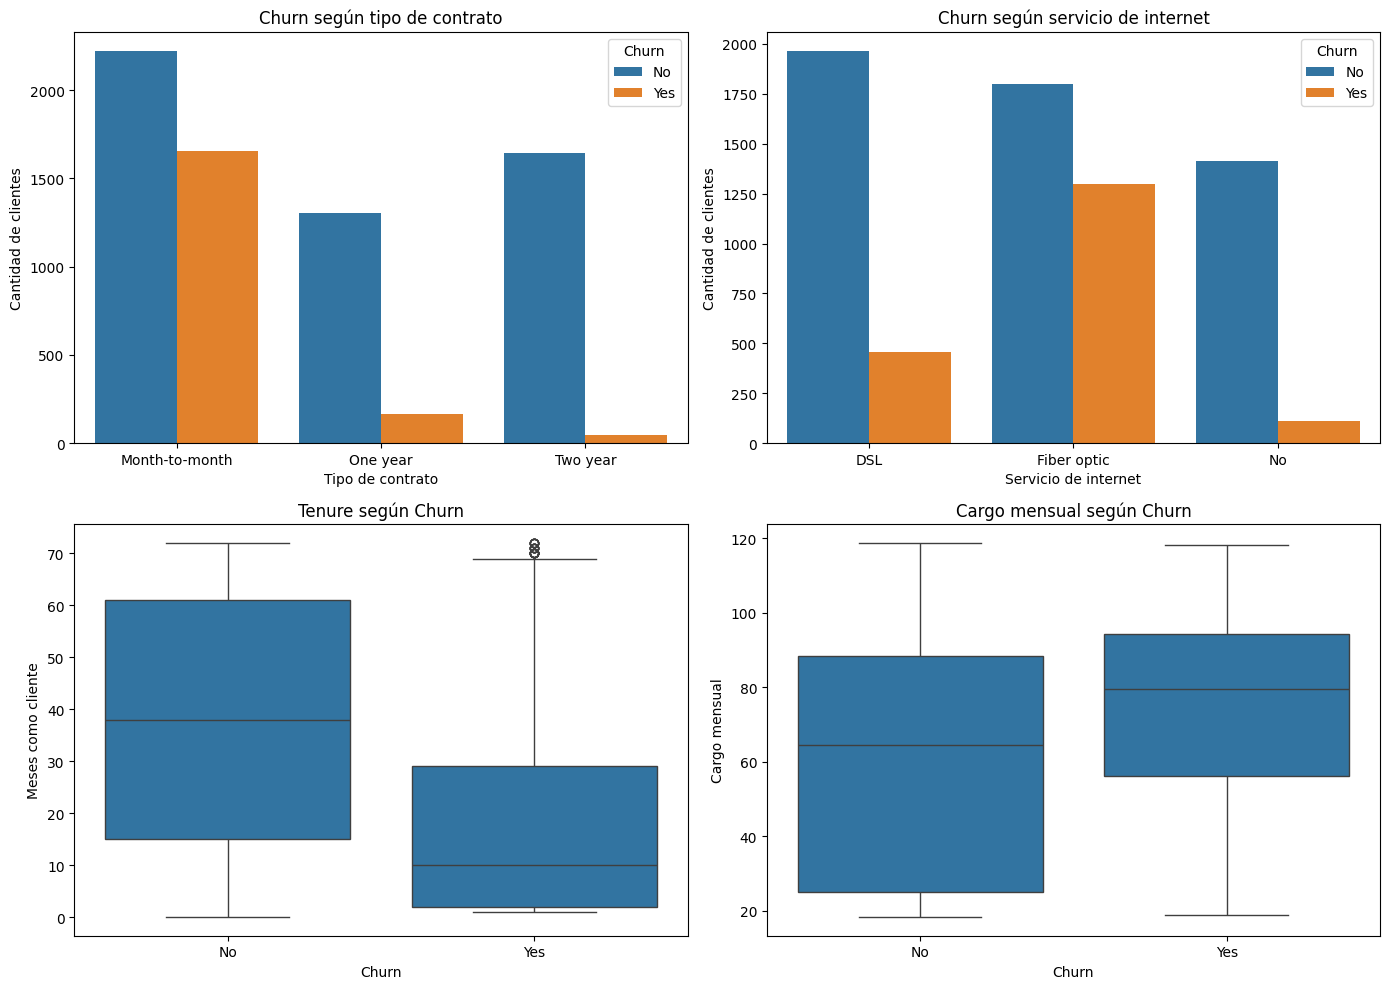

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))

sns.countplot(data=dfpd, x="Contract", hue="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Churn según tipo de contrato")
axes[0, 0].set_xlabel("Tipo de contrato")
axes[0, 0].set_ylabel("Cantidad de clientes")

sns.countplot(data=dfpd, x="InternetService", hue="Churn", ax=axes[0, 1])
axes[0, 1].set_title("Churn según servicio de internet")
axes[0, 1].set_xlabel("Servicio de internet")
axes[0, 1].set_ylabel("Cantidad de clientes")

sns.boxplot(data=dfpd, x="Churn", y="tenure", ax=axes[1, 0])
axes[1, 0].set_title("Tenure según Churn")
axes[1, 0].set_xlabel("Churn")
axes[1, 0].set_ylabel("Meses como cliente")

sns.boxplot(data=dfpd, x="Churn", y="MonthlyCharges", ax=axes[1, 1])
axes[1, 1].set_title("Cargo mensual según Churn")
axes[1, 1].set_xlabel("Churn")
axes[1, 1].set_ylabel("Cargo mensual")

plt.tight_layout()

Interpretación:
- **Contrato:** en los contratos month to month se va una parte muy grande de los clientes (cerca del 43%), mientras que en los de uno y dos años casi no hay bajas (11% y 3%). Es la variable que más diferencia a los que se van de los que se quedan.
- **Internet:** con fibra óptica se va mucho más gente (cerca del 42%) que con DSL (19%) o sin internet (7%).
- **Tenure:** los clientes que se van llevan poco tiempo en la empresa (la mitad se fue antes de los 10 meses), mientras que los que se quedan tienen una antigüedad mucho mayor (mediana de 38 meses).
- **Cargo mensual:** los que se van pagan en promedio más por mes que los que se quedan.
- **Outliers:** en las variables numéricas no hay outliers importantes; solo unos pocos puntos aislados en tenure de los que se van, que son valores válidos (clientes antiguos que igual se fueron), por lo que no se elimina nada.

In [ ]:
churn_counts = dfpd['Churn'].value_counts()
churn_pct = dfpd['Churn'].value_counts(normalize=True) * 100
resumen_balance = pd.DataFrame({'Clientes': churn_counts, 'Porcentaje (%)': churn_pct.round(2)})
display(resumen_balance)

,Clientes,Porcentaje (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


Interpretación: el dataset está moderadamente desbalanceado: el 73,5% de los clientes no se da de baja (Churn = No) y solo el 26,5% sí lo hace (Churn = Yes). No es un caso tan extremo como el fraude bancario (99,9% vs 0,1%), pero igual es suficiente para que la Accuracy sea una métrica engañosa: un modelo trivial que siempre prediga "No churn" ya acertaría el 73,5% de las veces sin identificar jamás a un solo cliente en riesgo de fuga. Por eso, en este informe priorizamos F1-Score, Recall, AUC-ROC y la curva Precision-Recall por sobre la Accuracy a la hora de comparar modelos.

## 3. Preprocesamiento y Feature Engineering

In [ ]:
# Variable objetivo en números: 1 = el cliente se fue, 0 = se quedó
def churnbinario(churn):
    if churn == 'Yes':
        return 1
    else:
        return 0

dfpd["Churn_binario"] = dfpd["Churn"].apply(churnbinario)
display(dfpd["Churn_binario"].head(10))

,Churn_binario
0,0
1,0
2,1
3,0
4,1
5,1
6,0
7,0
8,1
9,0


**Selección de variables.** Para el modelo se usan:
- `Contract` e `InternetService`: en el EDA se vio que el churn cambia mucho según el tipo de contrato y el servicio de internet.
- `tenure` y `MonthlyCharges`: los clientes que se van tienen menos antigüedad y pagan un cargo mensual más alto.

Se descartan:
- `customerID`: es solo un identificador, no dice nada sobre si el cliente se va.
- `TotalCharges`: es casi `tenure` por `MonthlyCharges` (correlación de 0,83 con tenure), así que repite información que ya está en el modelo.
- `gender`, `PhoneService` y `MultipleLines`: no parecen tener relación con que un cliente se vaya.
- El resto de los servicios adicionales (seguridad online, soporte técnico, etc.) y las variables personales (pareja, dependientes): se dejan afuera para mantener un modelo simple, pero podrían sumarse a futuro.

**Transformaciones:** codificación one-hot de las categóricas y estandarización de las numéricas (tenure y MonthlyCharges), porque están en escalas muy distintas.

In [ ]:
# Selección de variables predictoras y codificación de categóricas
X = pd.get_dummies(
    dfpd[["InternetService", "Contract", "tenure", "MonthlyCharges"]],
    columns=["InternetService", "Contract"],
    drop_first=True
)
y = dfpd["Churn_binario"]

# División train/test (80/20), evaluación siempre sobre X_test / y_test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Escalado de variables numéricas (ajustado SOLO con train, aplicado a train y test)
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()
X_train_scaled[['tenure', 'MonthlyCharges']] = scaler.fit_transform(X_train_scaled[['tenure', 'MonthlyCharges']])
X_test_scaled[['tenure', 'MonthlyCharges']] = scaler.transform(X_test_scaled[['tenure', 'MonthlyCharges']])

Interpretación: se usan InternetService, Contract, tenure y MonthlyCharges como predictoras, con codificación one-hot(drop_first=True para evitar colinealidad) para las categóricas. Se consideran las más importantes para predecir el Churn. El escalado (StandardScaler) se ajusta únicamente con X_train y luego se aplica a X_train y X_test, evitando data leakage del set de prueba hacia el entrenamiento. Los modelos se entrenan sobre la variable (X_train_scaled) y se evalúan siempre sobre los mismos datos de prueba (X_test_scaled, y_test), nunca sobre los datos de entrenamiento, para que las métricas reflejen la capacidad real de generalización y no un resultado artificialmente perfecto.

## 4. Modelado y Evaluación

**Modelo 1: Random Forest.** Se usa `class_weight="balanced"` porque hay muchos menos clientes que se van que clientes que se quedan.

In [ ]:
# Modelo 1: Random Forest
rf = RandomForestClassifier(
    n_estimators=200, max_depth=4, min_samples_leaf=5,
    class_weight="balanced", random_state=42
)
rf.fit(X_train_scaled, y_train)
rf.predict(X_test_scaled)
rf.predict_proba(X_test_scaled)


print("Model scores:")
print("Accuracy:", round(rf.score(X_test_scaled, y_test), 3))
print("F1 score:", round(f1_score(y_test, rf.predict(X_test_scaled)), 3))
print("Recall:", round(recall_score(y_test, rf.predict(X_test_scaled)), 3))
print("Precision:", round(precision_score(y_test, rf.predict(X_test_scaled), zero_division=0), 3))
mat_conf = confusion_matrix(y_test, rf.predict(X_test_scaled))
print("Confusion Matrix:")
print(mat_conf)

Model scores:
Accuracy: 0.749
F1 score: 0.644
Recall: 0.855
Precision: 0.516
Confusion Matrix:
[[737 299]
 [ 54 319]]


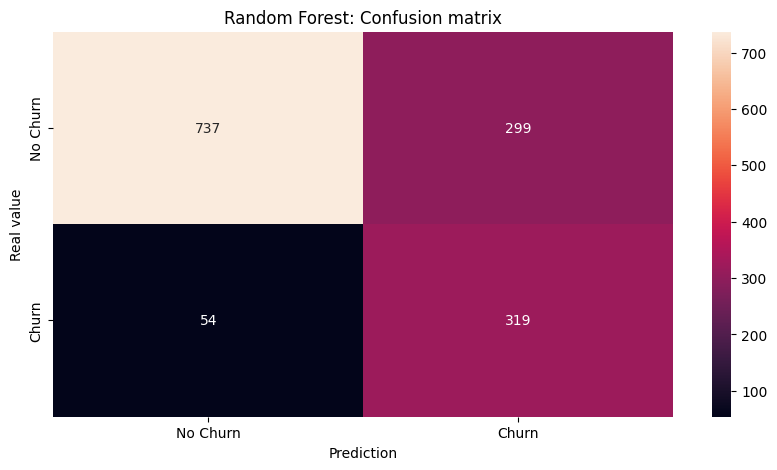

In [ ]:
# Matriz de confusión del Random Forest
plt.figure(figsize=(10,5))
sns.heatmap(mat_conf, annot=True, fmt="d", xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title('Random Forest: Confusion matrix')
plt.xlabel('Prediction')
plt.ylabel('Real value')
plt.show()

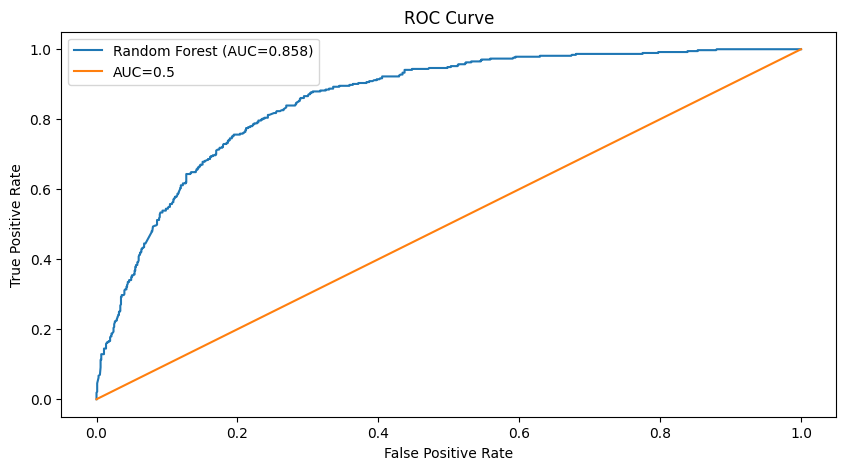

In [ ]:
# Curva ROC del Random Forest (con el AUC)
Roccurve= roc_curve(y_test, rf.predict_proba(X_test_scaled)[:, 1])
auc_rf = roc_auc_score(y_test, rf.predict_proba(X_test_scaled)[:, 1])
plt.figure(figsize=(10,5))
plt.plot(Roccurve[0], Roccurve[1], label=f'Random Forest (AUC={auc_rf:.3f})')
plt.plot([0, 1], [0, 1], label="AUC=0.5")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

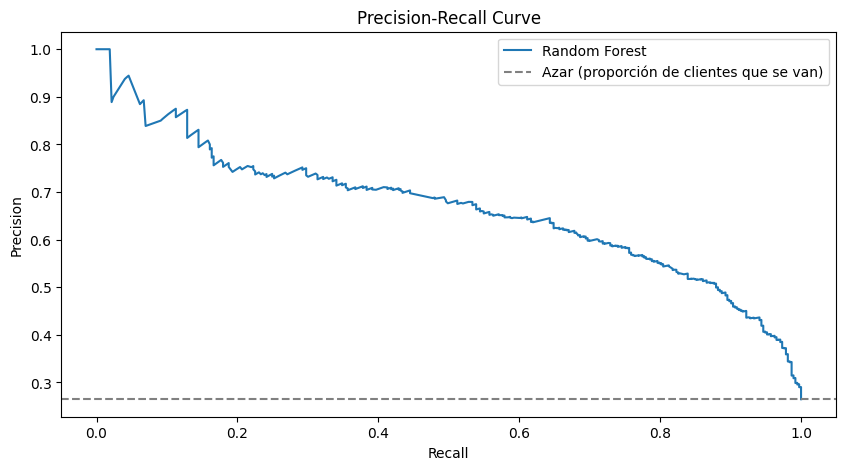

In [ ]:
# Curva Precision-Recall del Random Forest
precision, recall, _ = precision_recall_curve(y_test, rf.predict_proba(X_test_scaled)[:, 1])
plt.figure(figsize=(10,5))
plt.plot(recall, precision, label='Random Forest')
plt.axhline(y_test.mean(), linestyle='--', color='gray', label='Azar (proporción de clientes que se van)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

Interpretación del Random Forest:
- **Accuracy (0,75):** parece buena, pero un modelo que siempre dijera "no se va" acertaría el 73,5% de las veces, así que por sí sola no sirve.
- **Recall (0,86):** el modelo detecta a la gran mayoría de los clientes que realmente se van. En la matriz de confusión se ve que son pocos los que se le escapan (54 de 373).
- **Precision (0,52):** de los clientes que el modelo marca como "se va", más o menos la mitad en realidad se queda (falsas alarmas).
- **F1 (0,64):** resume el equilibrio entre precision y recall.
- **AUC-ROC (0,86):** la curva ROC está claramente por encima de la línea de azar (AUC de 0,5), es decir que el modelo distingue bastante bien a los que se van de los que se quedan.
- **Curva Precision-Recall:** muestra el equilibrio entre las dos métricas: cuando se le pide al modelo detectar más clientes que se van (más recall), la precision baja. Con un recall de alrededor de 0,86 la precision queda cerca de 0,5, y siempre se mantiene por encima de la línea de azar (0,26).

Para la empresa es más grave perder a un cliente sin darse cuenta que ofrecerle una promoción a alguien que no se iba, por lo que priorizar el recall es razonable.

**Modelo 2: Regresión Logística.** Se entrena y se evalúa igual que el Random Forest (mismos datos, mismo `class_weight`) para poder compararlos.

In [ ]:
# Modelo 2: Regresión Logística
lr = LogisticRegression(class_weight="balanced", random_state=42)
lr.fit(X_train_scaled, y_train)

print("Model scores:")
print("Accuracy:", round(lr.score(X_test_scaled, y_test), 3))
print("F1 score:", round(f1_score(y_test, lr.predict(X_test_scaled)), 3))
print("Recall:", round(recall_score(y_test, lr.predict(X_test_scaled)), 3))
print("Precision:", round(precision_score(y_test, lr.predict(X_test_scaled), zero_division=0), 3))
mat_conf_lr = confusion_matrix(y_test, lr.predict(X_test_scaled))
print("Confusion Matrix:")
print(mat_conf_lr)

Model scores:
Accuracy: 0.738
F1 score: 0.628
Recall: 0.836
Precision: 0.503
Confusion Matrix:
[[728 308]
 [ 61 312]]


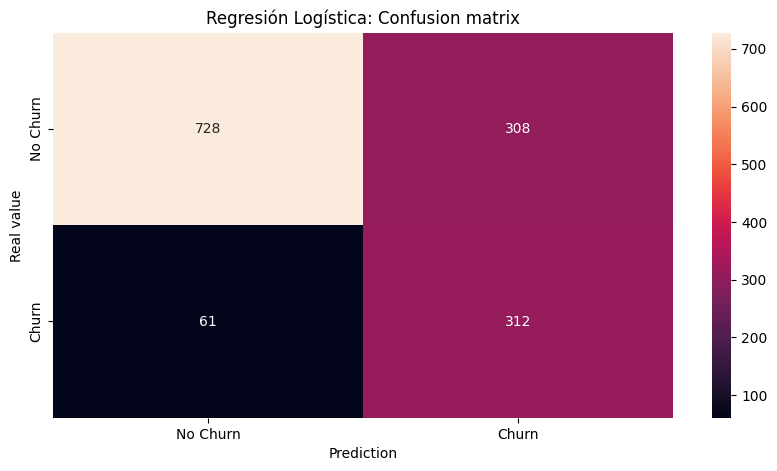

In [ ]:
# Matriz de confusión de la Regresión Logística
plt.figure(figsize=(10,5))
sns.heatmap(mat_conf_lr, annot=True, fmt="d", xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title('Regresión Logística: Confusion matrix')
plt.xlabel('Prediction')
plt.ylabel('Real value')
plt.show()

Comparación de los modelos: los resultados son casi iguales. El Random Forest queda un poco mejor en recall (0,86 contra 0,84) y en F1 (0,64 contra 0,63), y en las demás son muy parecidos. Como lo más importante es detectar a los clientes que se van, el **Random Forest** es el modelo elegido, aunque la Regresión Logística, más simple, es una alternativa válida. Que dos modelos distintos den resultados parecidos indica que el límite está en la información que se usó (solo cuatro variables) y no tanto en el modelo.

## 5. Conclusiones y Recomendaciones

**¿Qué aprendimos de los datos?**
- Aproximadamente 1 de cada 4 clientes se va (26,5%). Como hay más clientes que se quedan, la accuracy sola engaña y se evalúa también con recall, precision y F1.
- El **tipo de contrato** es lo que más diferencia a los clientes: con contrato mensual se va cerca del 43%, con contratos de uno o dos años menos del 12%.
- Se van más los **clientes nuevos** (la mitad se fue antes de los 10 meses) y los que tienen **fibra óptica** (cerca del 42%), que además es el servicio más caro.
- Con solo cuatro variables, el Random Forest detecta a más de 8 de cada 10 clientes que se van.

**¿Qué acción debería tomar el negocio?**
1. Usar el modelo para armar una lista de clientes con riesgo de irse y contactarlos con una oferta de retención. Como más o menos la mitad de las alertas son falsas alarmas, conviene que la oferta sea de bajo costo.
2. Ofrecer beneficios para que los clientes con contrato mensual pasen a contratos de uno o dos años.
3. Cuidar especialmente a los clientes en sus primeros meses (seguimiento, atención), que es cuando más se van.
4. Revisar el servicio de fibra óptica (precio, calidad, soporte) por su alta tasa de bajas.

**Limitaciones y mejoras futuras**
- El modelo usa solo cuatro variables; se podrían sumar otras como soporte técnico, seguridad online o método de pago, y las que se eliminaron al principio.
- Se probó una sola división de los datos en train y test; con otras divisiones los resultados podrían variar un poco.
- Casi la mitad de las alertas del modelo son falsas alarmas; se podría mejorar la precision probando otros modelos o ajustando sus parámetros.
- No se tiene el costo de una campaña de retención ni lo que vale cada cliente, necesarios para calcular cuánto ganaría realmente la empresa.
- Los datos son de un momento puntual y muestran relaciones, no causas: por ejemplo, no sabemos por qué se van los clientes de fibra óptica.